# 1단계 전처리 통합 파이프라인


## 0. 라이브러리, 경로, 공통 유틸 함수

In [13]:
from pathlib import Path

CUR_DIR = Path.cwd().resolve()
BASE_DIR = CUR_DIR / "data"

In [14]:
import os
import pandas as pd
import numpy as np

DATA_DIR = BASE_DIR 
OUT_DIR = BASE_DIR                 
os.makedirs(OUT_DIR, exist_ok=True)

JOIN_KEY_ABC = ['기준_년분기_코드', '상권_코드', '서비스_업종_코드']
JOIN_KEY_AB = ['기준_년분기_코드', '상권_코드']

EN2KR = {
    'stdr_yyqu_cd': '기준_년분기_코드',
    'trdar_se_cd': '상권_구분_코드',
    'trdar_se_cd_nm': '상권_구분_코드_명',
    'trdar_cd': '상권_코드',
    'trdar_cd_nm': '상권_코드_명',
    'svc_induty_cd': '서비스_업종_코드',
    'svc_induty_cd_nm': '서비스_업종_코드_명',
    'stor_co': '점포_수',
    'similr_induty_stor_co': '유사_업종_점포_수',
    'opbiz_rt': '개업_율',
    'opbiz_stor_co': '개업_점포_수',
    'clsbiz_rt': '폐업_률',
    'clsbiz_stor_co': '폐업_점포_수',
    'frc_stor_co': '프랜차이즈_점포_수',
}


def read_csv_safe(path):
    for enc in ['cp949', 'utf-8']:
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"인코딩 판별 실패: {path}")


def load_and_clean(filename, is_english=False):
    df = read_csv_safe(os.path.join(DATA_DIR, filename))
    if is_english:
        df = df.rename(columns=EN2KR)
    return df


def safe_div(numerator, denominator):
    result = numerator / denominator
    result = result.replace([np.inf, -np.inf], np.nan)
    return result


## 1단계: 원본 데이터 병합

### 1-1. 점포-상권 (2021~2025) 정리 + 병합

In [15]:
store_files = {
    2021: '서울시_상권분석서비스(점포-상권)_2021년.csv',
    2022: '서울시_상권분석서비스(점포-상권)_2022년.csv',
    2023: '서울시_상권분석서비스(점포-상권)_2023년.csv',
    2024: '서울시 상권분석서비스(점포-상권)_2024년.csv',
    2025: '서울시 상권분석서비스(점포-상권)_2025년.csv',
}

store_dfs = []
for year, fname in store_files.items():
    is_en = (year == 2025)  
    df_ = load_and_clean(fname, is_english=is_en)
    store_dfs.append(df_)

store_df = pd.concat(store_dfs, ignore_index=True)
print(f"[점포-상권] 병합 완료: {store_df.shape}")
print(f"분기범위: {store_df['기준_년분기_코드'].min()} ~ {store_df['기준_년분기_코드'].max()}")

dup_cnt = store_df.duplicated(subset=JOIN_KEY_ABC).sum()
print(f"[점포-상권] 키 중복 행 수: {dup_cnt}")
if dup_cnt > 0:
    store_df = store_df.drop_duplicates(subset=JOIN_KEY_ABC, keep='last')
    print(f"  -> 중복 제거 후: {store_df.shape}")


[점포-상권] 병합 완료: (1528872, 14)
분기범위: 20211 ~ 20254
[점포-상권] 키 중복 행 수: 0


### 1-2. 추정매출-상권 (2021~2025) 정리 + 병합

In [16]:
sales_files = {
    2021: '서울시_상권분석서비스(추정매출-상권)_2021년.csv',
    2022: '서울시_상권분석서비스(추정매출-상권)_2022년.csv',
    2023: '서울시_상권분석서비스(추정매출-상권)_2023년.csv',
    2024: '서울시 상권분석서비스(추정매출-상권)_2024년.csv',
    2025: '서울시 상권분석서비스(추정매출-상권)_2025년.csv',
}

sales_dfs = []
for year, fname in sales_files.items():
    df_ = load_and_clean(fname, is_english=False)
    sales_dfs.append(df_)

sales_df = pd.concat(sales_dfs, ignore_index=True)
print(f"[추정매출-상권] 병합 완료: {sales_df.shape}")
print(f"분기범위: {sales_df['기준_년분기_코드'].min()} ~ {sales_df['기준_년분기_코드'].max()}")

dup_cnt = sales_df.duplicated(subset=JOIN_KEY_ABC).sum()
print(f"[추정매출-상권] 키 중복 행 수: {dup_cnt}")
if dup_cnt > 0:
    sales_df = sales_df.drop_duplicates(subset=JOIN_KEY_ABC, keep='last')

sales_core_cols = JOIN_KEY_ABC + [
    '당월_매출_금액', '당월_매출_건수',
    '주중_매출_금액', '주말_매출_금액',
    '남성_매출_금액', '여성_매출_금액',
]
sales_core_cols = [c for c in sales_core_cols if c in sales_df.columns]
sales_df = sales_df[sales_core_cols]


[추정매출-상권] 병합 완료: (439141, 55)
분기범위: 20211 ~ 20254
[추정매출-상권] 키 중복 행 수: 0


### 1-3. 레벨 A 병합: 점포-상권 + 추정매출-상권

In [17]:
base_df = store_df.merge(sales_df, on=JOIN_KEY_ABC, how='left', suffixes=('', '_매출'))
print(f"[레벨A 병합: 점포+매출] shape: {base_df.shape}")

miss_rate = base_df['당월_매출_금액'].isna().mean()
print(f"매출 결측률: {miss_rate:.1%}  (매출 미제공 38개 업종 때문 - 정상)")


[레벨A 병합: 점포+매출] shape: (1528872, 20)
매출 결측률: 71.3%  (매출 미제공 38개 업종 때문 - 정상)


### 1-4. 레벨 B: 상권×분기 단위 데이터 정리

In [18]:
level_b_files = {
    '소비-상권': '서울시 상권분석서비스(소비-상권).csv',
    '길단위인구-상권': '서울시 상권분석서비스(길단위인구-상권).csv',
    '상주인구-상권': '서울시 상권분석서비스(상주인구-상권).csv',
    '직장인구-상권': '서울시 상권분석서비스(직장인구-상권).csv',
    '집객시설-상권': '서울시 상권분석서비스(집객시설-상권).csv',
}

level_b_dfs = {}
for name, fname in level_b_files.items():
    df_ = load_and_clean(fname, is_english=False)

    dup_cnt = df_.duplicated(subset=JOIN_KEY_AB).sum()
    if dup_cnt > 0:
        df_ = df_.drop_duplicates(subset=JOIN_KEY_AB, keep='last')

    meta_cols = ['상권_구분_코드', '상권_구분_코드_명', '상권_코드_명']
    df_ = df_.drop(columns=[c for c in meta_cols if c in df_.columns])

    level_b_dfs[name] = df_
    print(f"[{name}] shape: {df_.shape}, 키 중복 제거: {dup_cnt}")


[소비-상권] shape: (34170, 12), 키 중복 제거: 0
[길단위인구-상권] shape: (34633, 24), 키 중복 제거: 0
[상주인구-상권] shape: (34275, 26), 키 중복 제거: 0
[직장인구-상권] shape: (34386, 23), 키 중복 제거: 0
[집객시설-상권] shape: (33138, 22), 키 중복 제거: 0


### 1-5. 레벨 A(base) + 레벨 B 전부 병합 (broadcast merge)

In [19]:
final_df = base_df.copy()

for name, df_ in level_b_dfs.items():
    before_rows = len(final_df)
    final_df = final_df.merge(df_, on=JOIN_KEY_AB, how='left')
    assert len(final_df) == before_rows, f"{name} 병합 중 행 수 변경됨 - 중복 키 의심"
    print(f"[{name}] 병합 후 shape: {final_df.shape}")

print(f"\n최종 병합 shape: {final_df.shape}")
print(f"분기 범위: {final_df['기준_년분기_코드'].min()} ~ {final_df['기준_년분기_코드'].max()}")

missing_check_cols = ['총_유동인구_수', '지출_총금액', '총_상주인구_수',
                       '총_직장_인구_수', '집객시설_수']
for c in missing_check_cols:
    if c in final_df.columns:
        miss_rate = final_df[c].isna().mean()
        print(f"  {c} 결측률: {miss_rate:.2%}")


[소비-상권] 병합 후 shape: (1528872, 30)
[길단위인구-상권] 병합 후 shape: (1528872, 52)
[상주인구-상권] 병합 후 shape: (1528872, 76)
[직장인구-상권] 병합 후 shape: (1528872, 97)
[집객시설-상권] 병합 후 shape: (1528872, 117)

최종 병합 shape: (1528872, 117)
분기 범위: 20211 ~ 20254
  총_유동인구_수 결측률: 0.01%
  지출_총금액 결측률: 2.32%
  총_상주인구_수 결측률: 0.59%
  총_직장_인구_수 결측률: 0.30%
  집객시설_수 결측률: 1.81%


### 1-6. 체크포인트 저장 (선택)

In [ ]:
checkpoint_path = os.path.join(OUT_DIR, "1단계_병합데이터.csv")

if os.path.exists(checkpoint_path):
    print(f"기존 체크포인트를 불러옵니다: {checkpoint_path}")
    final_df = read_csv_safe(checkpoint_path)
    print(f"불러온 shape: {final_df.shape}")
else:
    final_df.to_csv(
        checkpoint_path,
        index=False,
        encoding="utf-8-sig"
    )
    print(f"체크포인트 저장 완료: {checkpoint_path}")
    print(f"저장한 shape: {final_df.shape}")

체크포인트 저장 완료: .\data\1단계_병합데이터.csv
shape: (1528872, 117)


## 2단계: 컬럼 정리 및 y 라벨 생성

### 2-1. 코드-이름 중복 컬럼(`_명`) 삭제

In [21]:
df = final_df.copy()
print(f"불러오기 전 shape: {df.shape}")

drop_cols = ['상권_구분_코드_명', '상권_코드_명', '서비스_업종_코드_명']
drop_cols = [c for c in drop_cols if c in df.columns]

print(f"삭제 대상: {drop_cols}")
df = df.drop(columns=drop_cols)
print(f"삭제 후 shape: {df.shape}")


불러오기 전 shape: (1528872, 117)
삭제 대상: ['상권_구분_코드_명', '상권_코드_명', '서비스_업종_코드_명']
삭제 후 shape: (1528872, 114)


### 2-2. 매출 결측유형 플래그

In [22]:
upjong_has_sales = df.groupby('서비스_업종_코드')['당월_매출_금액'].apply(lambda s: s.notna().any())
covered_upjong = set(upjong_has_sales[upjong_has_sales].index)

df['매출결측유형'] = 0
mask_no_data = df['당월_매출_금액'].isna()
mask_never_covered = ~df['서비스_업종_코드'].isin(covered_upjong)

df.loc[mask_no_data & mask_never_covered, '매출결측유형'] = 1
df.loc[mask_no_data & ~mask_never_covered, '매출결측유형'] = 2

df['매출정보없음'] = (df['매출결측유형'] != 0).astype('int8')
df['매출결측유형'] = df['매출결측유형'].astype('int8')

print(df['매출결측유형'].value_counts().sort_index())


매출결측유형
0    439141
1    290442
2    799289
Name: count, dtype: int64


### 2-3. 파생변수 관점에서 불필요한 컬럼 추가 삭제

In [23]:
drop_cols_2 = ['개업_율']
drop_cols_2 += ['월요일_유동인구_수', '화요일_유동인구_수', '수요일_유동인구_수',
                '목요일_유동인구_수', '금요일_유동인구_수', '토요일_유동인구_수', '일요일_유동인구_수']
drop_cols_2 += [c for c in df.columns if ('남성연령대_' in c or '여성연령대_' in c)
                and ('상주인구' in c or '직장_인구' in c)]

drop_cols_2 = [c for c in drop_cols_2 if c in df.columns]
print(f"추가 삭제 대상 ({len(drop_cols_2)}개):")
for c in drop_cols_2:
    print(" -", c)

df = df.drop(columns=drop_cols_2)
print(f"\n삭제 후 shape: {df.shape}")


추가 삭제 대상 (32개):
 - 개업_율
 - 월요일_유동인구_수
 - 화요일_유동인구_수
 - 수요일_유동인구_수
 - 목요일_유동인구_수
 - 금요일_유동인구_수
 - 토요일_유동인구_수
 - 일요일_유동인구_수
 - 남성연령대_10_상주인구_수
 - 남성연령대_20_상주인구_수
 - 남성연령대_30_상주인구_수
 - 남성연령대_40_상주인구_수
 - 남성연령대_50_상주인구_수
 - 남성연령대_60_이상_상주인구_수
 - 여성연령대_10_상주인구_수
 - 여성연령대_20_상주인구_수
 - 여성연령대_30_상주인구_수
 - 여성연령대_40_상주인구_수
 - 여성연령대_50_상주인구_수
 - 여성연령대_60_이상_상주인구_수
 - 남성연령대_10_직장_인구_수
 - 남성연령대_20_직장_인구_수
 - 남성연령대_30_직장_인구_수
 - 남성연령대_40_직장_인구_수
 - 남성연령대_50_직장_인구_수
 - 남성연령대_60_이상_직장_인구_수
 - 여성연령대_10_직장_인구_수
 - 여성연령대_20_직장_인구_수
 - 여성연령대_30_직장_인구_수
 - 여성연령대_40_직장_인구_수
 - 여성연령대_50_직장_인구_수
 - 여성연령대_60_이상_직장_인구_수

삭제 후 shape: (1528872, 84)


### 2-4. 집객시설 결측값 처리

In [24]:
facility_detail_cols = ['관공서_수', '은행_수', '종합병원_수', '일반_병원_수', '약국_수', '유치원_수',
                        '초등학교_수', '중학교_수', '고등학교_수', '대학교_수', '백화점_수', '슈퍼마켓_수',
                        '극장_수', '숙박_시설_수', '공항_수', '철도_역_수', '버스_터미널_수', '지하철_역_수',
                        '버스_정거장_수']
facility_detail_cols = [c for c in facility_detail_cols if c in df.columns]

print(f"집객시설 세부유형 삭제 ({len(facility_detail_cols)}개): {facility_detail_cols}")
df = df.drop(columns=facility_detail_cols)

df['집객시설정보없음'] = df['집객시설_수'].isna().astype('int8')

print(f"\n삭제 후 shape: {df.shape}")
print(f"집객시설정보없음 == 1 인 행 수: {df['집객시설정보없음'].sum()}")


집객시설 세부유형 삭제 (19개): ['관공서_수', '은행_수', '종합병원_수', '일반_병원_수', '약국_수', '유치원_수', '초등학교_수', '중학교_수', '고등학교_수', '대학교_수', '백화점_수', '슈퍼마켓_수', '극장_수', '숙박_시설_수', '공항_수', '철도_역_수', '버스_터미널_수', '지하철_역_수', '버스_정거장_수']

삭제 후 shape: (1528872, 66)
집객시설정보없음 == 1 인 행 수: 27664


### 2-5. 나머지 레벨B(소비/유동인구/상주인구/직장인구) 결측 플래그 추가

In [25]:
df["유동인구정보없음"] = df["총_유동인구_수"].isna().astype("int8")
df["직장인구정보없음"] = df["총_직장_인구_수"].isna().astype("int8")
df["상주인구정보없음"] = df["총_상주인구_수"].isna().astype("int8")
df["소비정보없음"] = df["지출_총금액"].isna().astype("int8")

print(df[["유동인구정보없음", "직장인구정보없음", "상주인구정보없음", "소비정보없음", "집객시설정보없음"]].sum())
print(f"\n현재 컬럼 수: {len(df.columns)}개")


유동인구정보없음      170
직장인구정보없음     4606
상주인구정보없음     9001
소비정보없음      35539
집객시설정보없음    27664
dtype: int64

현재 컬럼 수: 70개


### 2-6. 폐업률 이상치 제거 + 다음 분기 y 라벨 생성

In [26]:
before = len(df)
df = df[df['폐업_률'] <= 100]
print(f"이상치 제거: {before - len(df)}행 제거 -> {df.shape}")
print(f"폐업_률 최댓값 확인: {df['폐업_률'].max()}")

def next_quarter(q):
    year, quarter = divmod(q, 10)
    if quarter == 4:
        return (year + 1) * 10 + 1
    return year * 10 + (quarter + 1)

df['다음분기코드'] = df['기준_년분기_코드'].apply(next_quarter)

label_df = df[['기준_년분기_코드', '상권_코드', '서비스_업종_코드', '폐업_률']].rename(
    columns={'기준_년분기_코드': '다음분기코드', '폐업_률': 'y_다음분기_폐업률'}
)
df = df.merge(label_df, on=['다음분기코드', '상권_코드', '서비스_업종_코드'], how='left')
df = df.drop(columns=['다음분기코드'])

print(f"y 없는 행: {df['y_다음분기_폐업률'].isna().sum()} ({df['y_다음분기_폐업률'].isna().mean():.1%})")
print("  (y가 없는 이유: 해당 상권x업종 조합이 다음 분기에 소멸했거나, 데이터의 마지막 분기라 다음 분기 자체가 없는 경우)")


이상치 제거: 723행 제거 -> (1528149, 70)
폐업_률 최댓값 확인: 100
y 없는 행: 86520 (5.7%)
  (y가 없는 이유: 해당 상권x업종 조합이 다음 분기에 소멸했거나, 데이터의 마지막 분기라 다음 분기 자체가 없는 경우)


### 2-7. 체크포인트 저장 + 학습용/예측대상 분리

In [27]:
checkpoint_path = os.path.join(OUT_DIR, "1단계_병합데이터_컬럼정리_전체.csv")
df.to_csv(checkpoint_path, index=False, encoding='utf-8-sig')
print(f"체크포인트 저장 완료: {checkpoint_path}")

train_df = df[df['y_다음분기_폐업률'].notna()].copy()
predict_df = df[df['y_다음분기_폐업률'].isna()].copy()

print(f"\n학습용 데이터(train_df) shape: {train_df.shape}")
print(f"예측 대상 데이터(predict_df) shape: {predict_df.shape}")
print(f"  predict_df 분기 범위: {predict_df['기준_년분기_코드'].min()} ~ {predict_df['기준_년분기_코드'].max()}")


체크포인트 저장 완료: .\data\1단계_병합데이터_컬럼정리_전체.csv

학습용 데이터(train_df) shape: (1441629, 71)
예측 대상 데이터(predict_df) shape: (86520, 71)
  predict_df 분기 범위: 20211 ~ 20254


## 3단계: 파생변수 생성

In [28]:
def make_derived_features(df_in):
    df_ = df_in.copy()

    df_['개업률'] = safe_div(df_['개업_점포_수'], df_['유사_업종_점포_수']) * 100
    df_['순증감_점포수'] = df_['개업_점포_수'] - df_['폐업_점포_수']
    df_['프랜차이즈_비율'] = safe_div(df_['프랜차이즈_점포_수'], df_['유사_업종_점포_수'])

    df_['객단가'] = safe_div(df_['당월_매출_금액'], df_['당월_매출_건수'])
    df_['주말_매출_비율'] = safe_div(df_['주말_매출_금액'], df_['당월_매출_금액'])
    df_['점포당_매출'] = safe_div(df_['당월_매출_금액'], df_['유사_업종_점포_수'])
    df_['매출_성비'] = safe_div(df_['남성_매출_금액'], df_['남성_매출_금액'] + df_['여성_매출_금액'])

    spend_categories = ['식료품', '의류_신발', '생활용품', '의료비', '교통', '여가', '문화', '교육', '유흥']
    for cat in spend_categories:
        col = f'{cat}_지출_총금액'
        if col in df_.columns:
            df_[f'{cat}_지출_비율'] = safe_div(df_[col], df_['지출_총금액'])
    df_['지출_대비_매출_비율'] = safe_div(df_['당월_매출_금액'], df_['지출_총금액'])

    df_['심야_유동인구_비율'] = safe_div(df_['시간대_21_24_유동인구_수'], df_['총_유동인구_수'])
    df_['20대_유동인구_비율'] = safe_div(df_['연령대_20_유동인구_수'], df_['총_유동인구_수'])
    df_['60대이상_유동인구_비율'] = safe_div(df_['연령대_60_이상_유동인구_수'], df_['총_유동인구_수'])
    df_['유동인구_대비_점포수'] = safe_div(df_['유사_업종_점포_수'], df_['총_유동인구_수'])

    df_['직장_상주_비율'] = safe_div(df_['총_직장_인구_수'], df_['총_상주인구_수'])
    df_['아파트_가구_비율'] = safe_div(df_['아파트_가구_수'], df_['총_가구_수'])
    df_['여성_상주인구_비율'] = safe_div(df_['여성_상주인구_수'], df_['총_상주인구_수'])

    return df_


train_df = make_derived_features(train_df)
predict_df = make_derived_features(predict_df)
print(f"파생변수 추가 후 train_df shape: {train_df.shape}")
print(f"파생변수 추가 후 predict_df shape: {predict_df.shape}")


파생변수 추가 후 train_df shape: (1441629, 95)
파생변수 추가 후 predict_df shape: (86520, 95)


### 3-1. 결측 정합성 최종 점검

In [29]:
spend_categories = ['식료품', '의류_신발', '생활용품', '의료비', '교통', '여가', '문화', '교육', '유흥']

checks = {
    '매출정보없음': ['객단가', '주말_매출_비율', '점포당_매출', '매출_성비'],
    '소비정보없음': [f'{c}_지출_비율' for c in spend_categories] + ['지출_대비_매출_비율'],
    '유동인구정보없음': ['심야_유동인구_비율', '20대_유동인구_비율', '60대이상_유동인구_비율', '유동인구_대비_점포수'],
}

for flag, cols in checks.items():
    for c in cols:
        if c in train_df.columns:
            mismatch = ((train_df[flag] == 1) & train_df[c].notna()).sum()
            status = "OK" if mismatch == 0 else f"불일치 {mismatch}건!"
            print(f"[{flag}] {c}: {status}")


[매출정보없음] 객단가: OK
[매출정보없음] 주말_매출_비율: OK
[매출정보없음] 점포당_매출: OK
[매출정보없음] 매출_성비: OK
[소비정보없음] 식료품_지출_비율: OK
[소비정보없음] 의류_신발_지출_비율: OK
[소비정보없음] 생활용품_지출_비율: OK
[소비정보없음] 의료비_지출_비율: OK
[소비정보없음] 교통_지출_비율: OK
[소비정보없음] 여가_지출_비율: OK
[소비정보없음] 문화_지출_비율: OK
[소비정보없음] 교육_지출_비율: OK
[소비정보없음] 유흥_지출_비율: OK
[소비정보없음] 지출_대비_매출_비율: OK
[유동인구정보없음] 심야_유동인구_비율: OK
[유동인구정보없음] 20대_유동인구_비율: OK
[유동인구정보없음] 60대이상_유동인구_비율: OK
[유동인구정보없음] 유동인구_대비_점포수: OK


In [30]:
checkpoint_path = os.path.join(OUT_DIR, "1단계_병합데이터_파생변수추가.csv")
train_df.to_csv(checkpoint_path, index=False, encoding='utf-8-sig')
print(f"체크포인트 저장 완료: {checkpoint_path}")


체크포인트 저장 완료: .\data\1단계_병합데이터_파생변수추가.csv


## 4단계: 다중공선성 컬럼 정리

In [31]:
def drop_multicollinear_features(df_in):
    df_ = df_in.copy()

    age_groups = ['10', '20', '30', '40', '50', '60_이상']
    for age in age_groups:
        df_[f'{age}대_상주인구_비율'] = safe_div(df_[f'연령대_{age}_상주인구_수'], df_['총_상주인구_수'])

    drop_cols = []
    drop_cols += ['남성_상주인구_수', '여성_상주인구_수']
    drop_cols += [f'연령대_{a}_상주인구_수' for a in age_groups]

    drop_cols += ['남성_유동인구_수', '여성_유동인구_수']


    drop_cols += ['아파트_가구_수', '비_아파트_가구_수', '아파트_가구_비율']

    drop_cols += ['주중_매출_금액', '주말_매출_금액', '남성_매출_금액', '여성_매출_금액']

    spend_categories = ['식료품', '의류_신발', '생활용품', '의료비', '교통', '여가', '문화', '교육', '유흥']
    drop_cols += [f'{c}_지출_총금액' for c in spend_categories]

    drop_cols += ['매출정보없음']

    drop_cols = sorted(set(c for c in drop_cols if c in df_.columns))
    df_ = df_.drop(columns=drop_cols)
    return df_, drop_cols


print(f"삭제 전 train_df shape: {train_df.shape}")
train_df, dropped = drop_multicollinear_features(train_df)
print(f"삭제 대상 {len(dropped)}개: {dropped}")
print(f"삭제 후 train_df shape: {train_df.shape}")

predict_df, _ = drop_multicollinear_features(predict_df)
print(f"삭제 후 predict_df shape: {predict_df.shape}")


삭제 전 train_df shape: (1441629, 95)
삭제 대상 27개: ['교육_지출_총금액', '교통_지출_총금액', '남성_매출_금액', '남성_상주인구_수', '남성_유동인구_수', '매출정보없음', '문화_지출_총금액', '비_아파트_가구_수', '생활용품_지출_총금액', '식료품_지출_총금액', '아파트_가구_비율', '아파트_가구_수', '여가_지출_총금액', '여성_매출_금액', '여성_상주인구_수', '여성_유동인구_수', '연령대_10_상주인구_수', '연령대_20_상주인구_수', '연령대_30_상주인구_수', '연령대_40_상주인구_수', '연령대_50_상주인구_수', '연령대_60_이상_상주인구_수', '유흥_지출_총금액', '의료비_지출_총금액', '의류_신발_지출_총금액', '주말_매출_금액', '주중_매출_금액']
삭제 후 train_df shape: (1441629, 74)
삭제 후 predict_df shape: (86520, 74)


### 4-1. 최종 저장

In [32]:
train_path = os.path.join(OUT_DIR, "1단계_학습데이터_최종.csv")
predict_path = os.path.join(OUT_DIR, "1단계_예측대상_최종.csv")

train_df.to_csv(train_path, index=False, encoding='utf-8-sig')
predict_df.to_csv(predict_path, index=False, encoding='utf-8-sig')

print(f"저장 완료: {train_path}  (shape: {train_df.shape})")
print(f"저장 완료: {predict_path}  (shape: {predict_df.shape})")


저장 완료: .\data\1단계_학습데이터_최종.csv  (shape: (1441629, 74))
저장 완료: .\data\1단계_예측대상_최종.csv  (shape: (86520, 74))


## 5단계: 최종 데이터 품질 검증 (선택 실행)

In [33]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = 'Malgun Gothic'  

ID_COLS = ['기준_년분기_코드', '상권_구분_코드', '상권_코드', '서비스_업종_코드']
Y_COL = 'y_다음분기_폐업률'
numeric_df = train_df.select_dtypes(include=[np.number])
print(f"검증 대상 shape: {train_df.shape}")


검증 대상 shape: (1441629, 74)


### 5-1. 결측률 + 무한대(inf) 확인

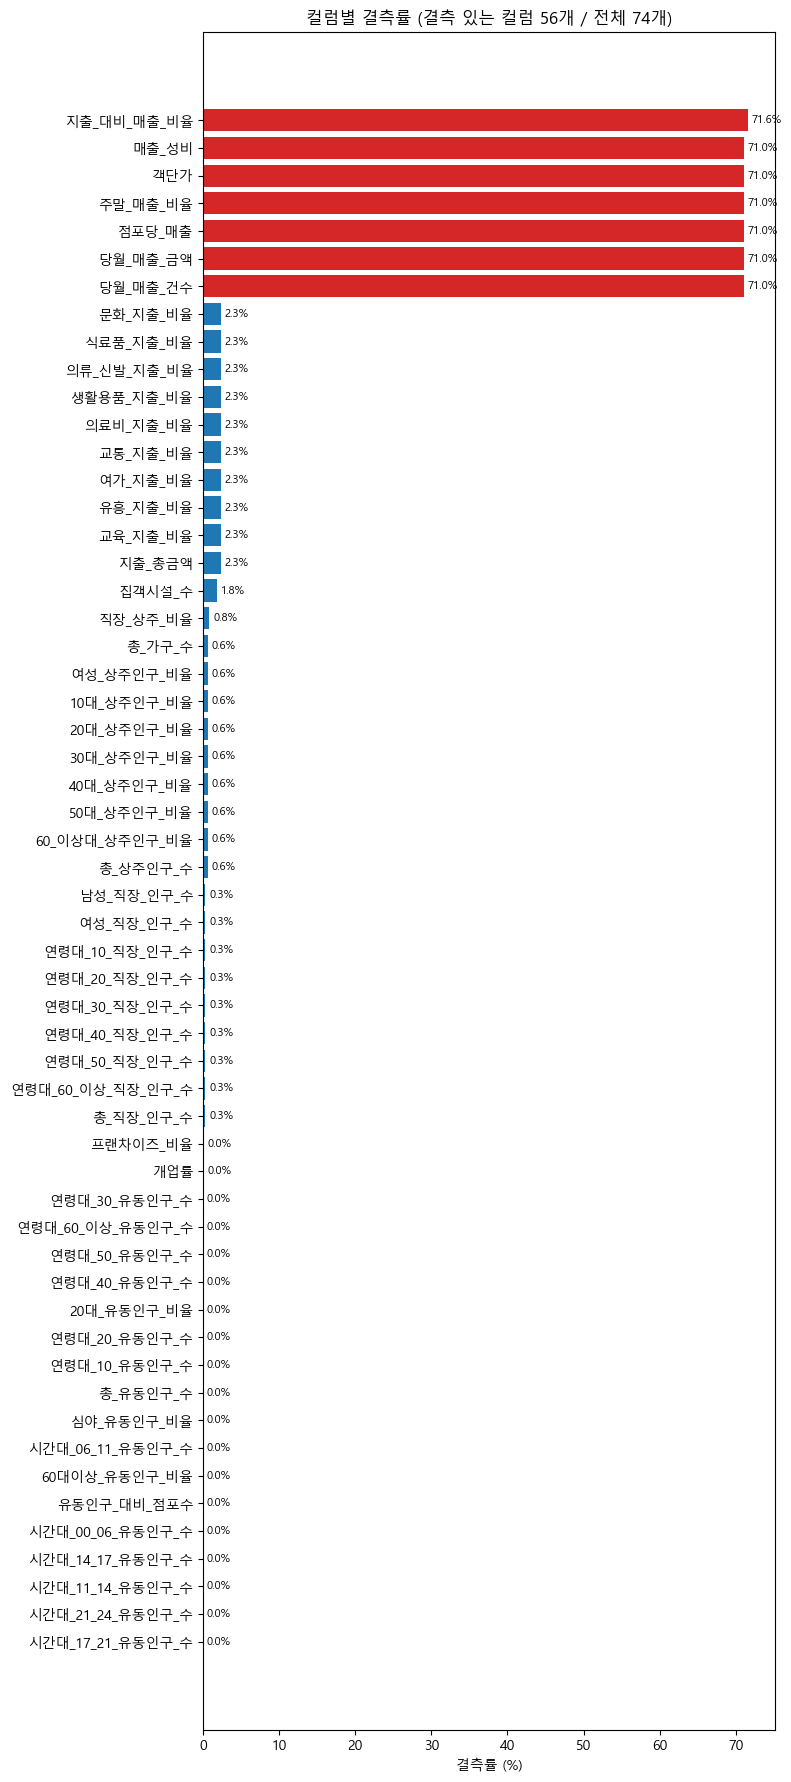

무한대(inf) 값을 가진 컬럼 없음 -> safe_div() 정상 작동


In [34]:
missing_rate = train_df.isna().mean().sort_values(ascending=False) * 100
missing_rate = missing_rate[missing_rate > 0]

fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(missing_rate))))
colors = ['#d62728' if v > 50 else '#ff7f0e' if v > 10 else '#1f77b4' for v in missing_rate.values]
ax.barh(missing_rate.index[::-1], missing_rate.values[::-1], color=colors[::-1])
ax.set_xlabel('결측률 (%)')
ax.set_title(f'컬럼별 결측률 (결측 있는 컬럼 {len(missing_rate)}개 / 전체 {train_df.shape[1]}개)')
for i, v in enumerate(missing_rate.values[::-1]):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=8)
plt.tight_layout()
plt.show()

inf_counts = numeric_df.isin([np.inf, -np.inf]).sum()
inf_counts = inf_counts[inf_counts > 0].sort_values(ascending=False)
if len(inf_counts) == 0:
    print("무한대(inf) 값을 가진 컬럼 없음 -> safe_div() 정상 작동")
else:
    print("무한대(inf) 값이 남아있는 컬럼:")
    print(inf_counts)


### 5-2. 파생변수 범위 검증 (0~1 벗어나는 비율 컬럼)

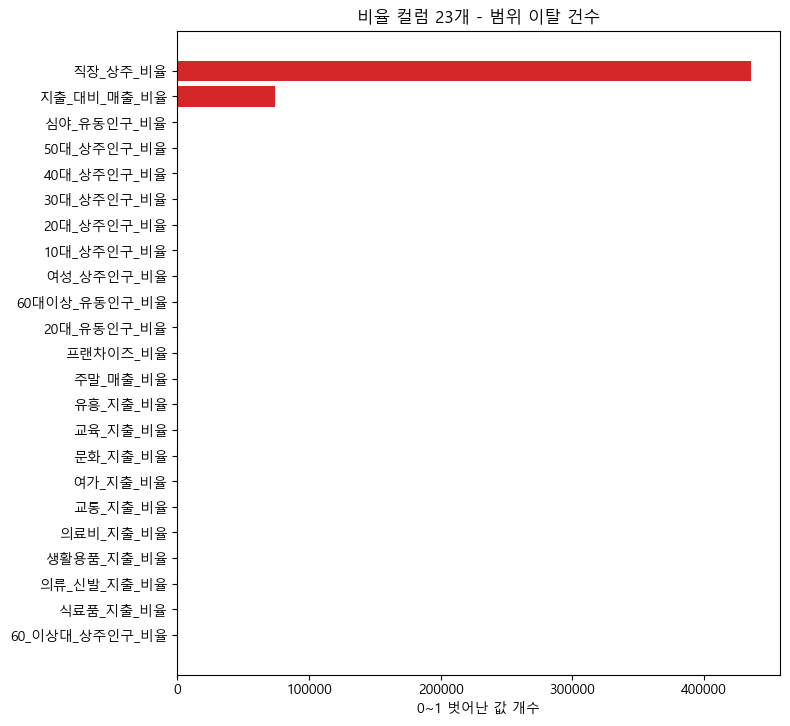

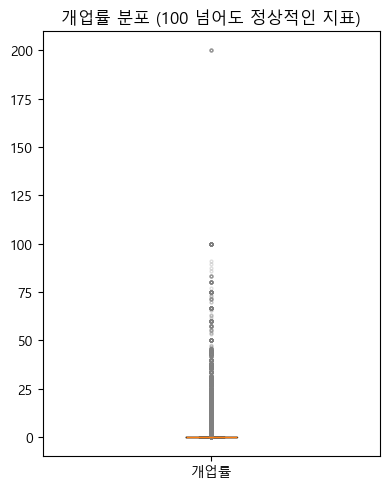

In [35]:
ratio_cols = [c for c in train_df.columns if '비율' in c]

oob_counts = pd.Series({c: int(((train_df[c] < 0) | (train_df[c] > 1)).sum()) for c in ratio_cols}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(oob_counts))))
colors = ['#d62728' if v > 0 else '#2ca02c' for v in oob_counts.values]
ax.barh(oob_counts.index[::-1], oob_counts.values[::-1], color=colors[::-1])
ax.set_xlabel('0~1 벗어난 값 개수')
ax.set_title(f'비율 컬럼 {len(ratio_cols)}개 - 범위 이탈 건수')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(4, 5))
ax.boxplot(train_df['개업률'].dropna(), tick_labels=['개업률'], showfliers=True,
           flierprops=dict(markersize=2, alpha=0.25, markeredgecolor='gray'))
ax.set_title('개업률 분포 (100 넘어도 정상적인 지표)')
plt.tight_layout()
plt.show()


### 5-3. 패널 연속성 (상권×업종 조합의 분기 연속 존재 여부)

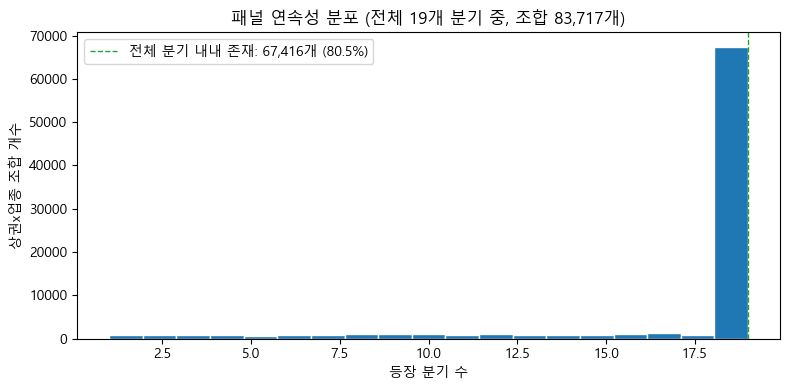

In [36]:
panel_counts = train_df.groupby(['상권_코드', '서비스_업종_코드'])['기준_년분기_코드'].nunique()
total_quarters = train_df['기준_년분기_코드'].nunique()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(panel_counts, bins=total_quarters, color='#1f77b4', edgecolor='white')
ax.set_xlabel('등장 분기 수')
ax.set_ylabel('상권x업종 조합 개수')
ax.set_title(f'패널 연속성 분포 (전체 {total_quarters}개 분기 중, 조합 {len(panel_counts):,}개)')
full_run = (panel_counts == total_quarters).sum()
ax.axvline(total_quarters, color='#2ca02c', linestyle='--', linewidth=1,
           label=f'전체 분기 내내 존재: {full_run:,}개 ({full_run/len(panel_counts)*100:.1f}%)')
ax.legend()
plt.tight_layout()
plt.show()


### 5-4. 상관관계 / 다중공선성 재확인

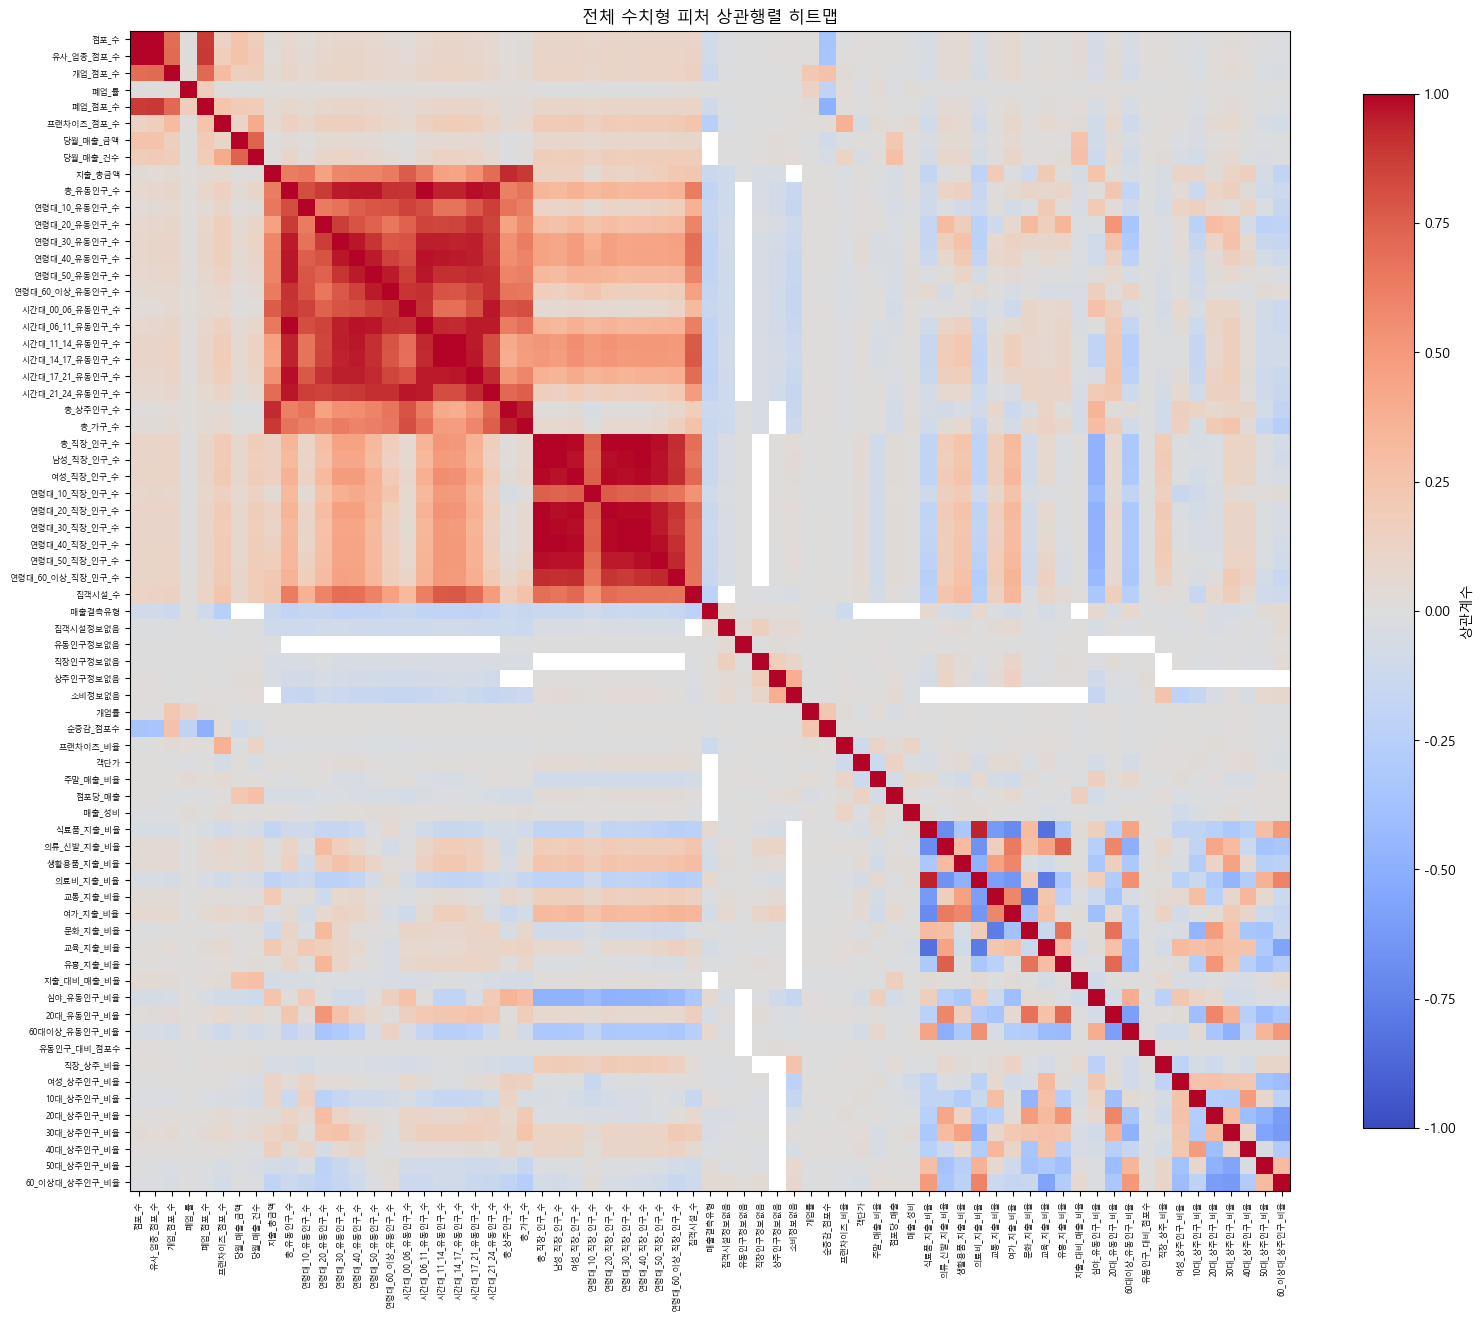

|상관계수| >= 0.9 쌍: 68개  ->  5개 그룹으로 묶임


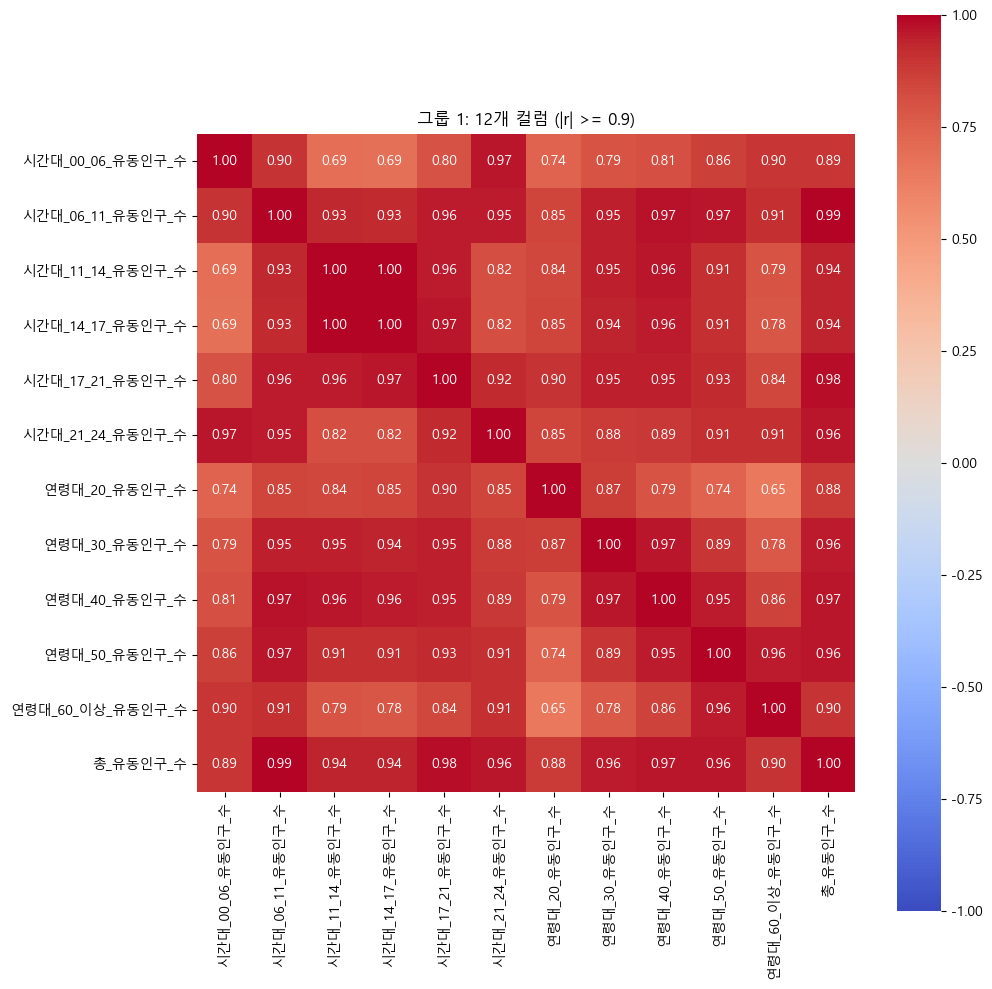

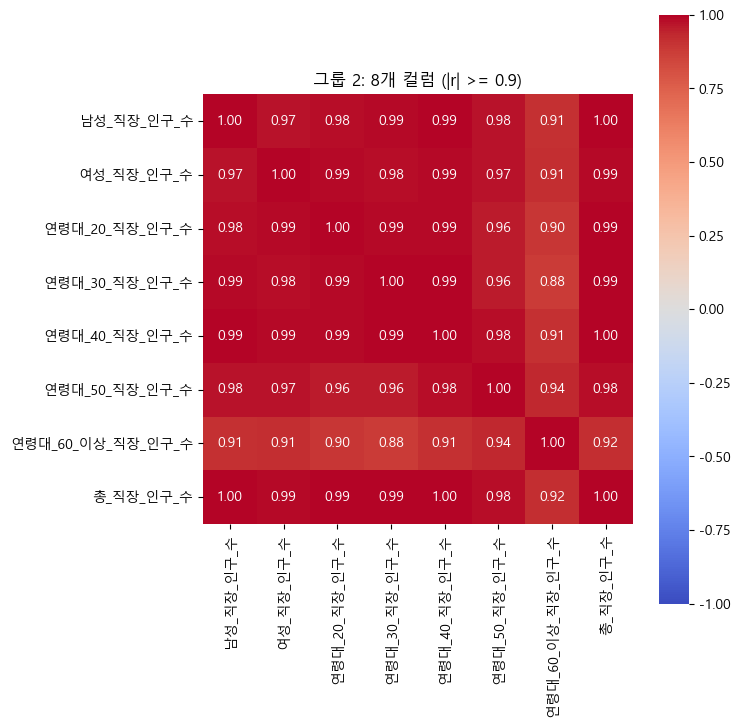

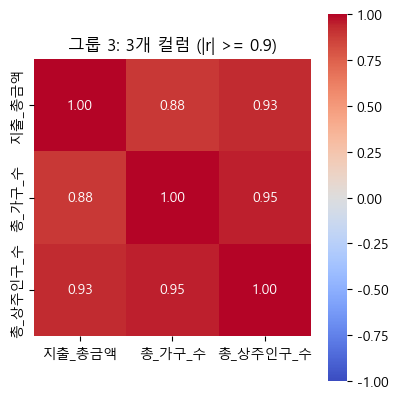

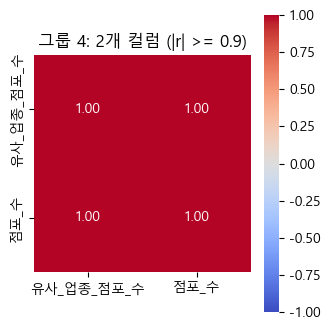

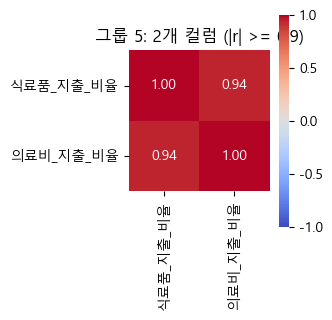

In [37]:
corr_cols = [c for c in numeric_df.columns if c not in ID_COLS and c != Y_COL]
corr = numeric_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8, label='상관계수')
ax.set_title('전체 수치형 피처 상관행렬 히트맵')
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack()
pairs = pairs[pairs.abs() >= 0.9]
high_corr_pairs = pairs.reset_index()
high_corr_pairs.columns = ['피처1', '피처2', '상관계수']

def connected_components(edge_list):
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb
    for a, b in edge_list:
        union(a, b)
    groups = {}
    for node in parent:
        groups.setdefault(find(node), set()).add(node)
    return list(groups.values())

groups = connected_components(high_corr_pairs[['피처1', '피처2']].values.tolist())
groups = sorted([g for g in groups if len(g) > 1], key=len, reverse=True)
print(f"|상관계수| >= 0.9 쌍: {len(high_corr_pairs)}개  ->  {len(groups)}개 그룹으로 묶임")

for i, g in enumerate(groups, 1):
    g = sorted(g)
    sub_corr = corr.loc[g, g]
    fig, ax = plt.subplots(figsize=(0.7 * len(g) + 2, 0.7 * len(g) + 2))
    sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                ax=ax, cbar=True, square=True)
    ax.set_title(f'그룹 {i}: {len(g)}개 컬럼 (|r| >= 0.9)')
    plt.tight_layout()
    plt.show()


### 5-5. 이상치 / 스케일 재점검 (파생변수 boxplot)

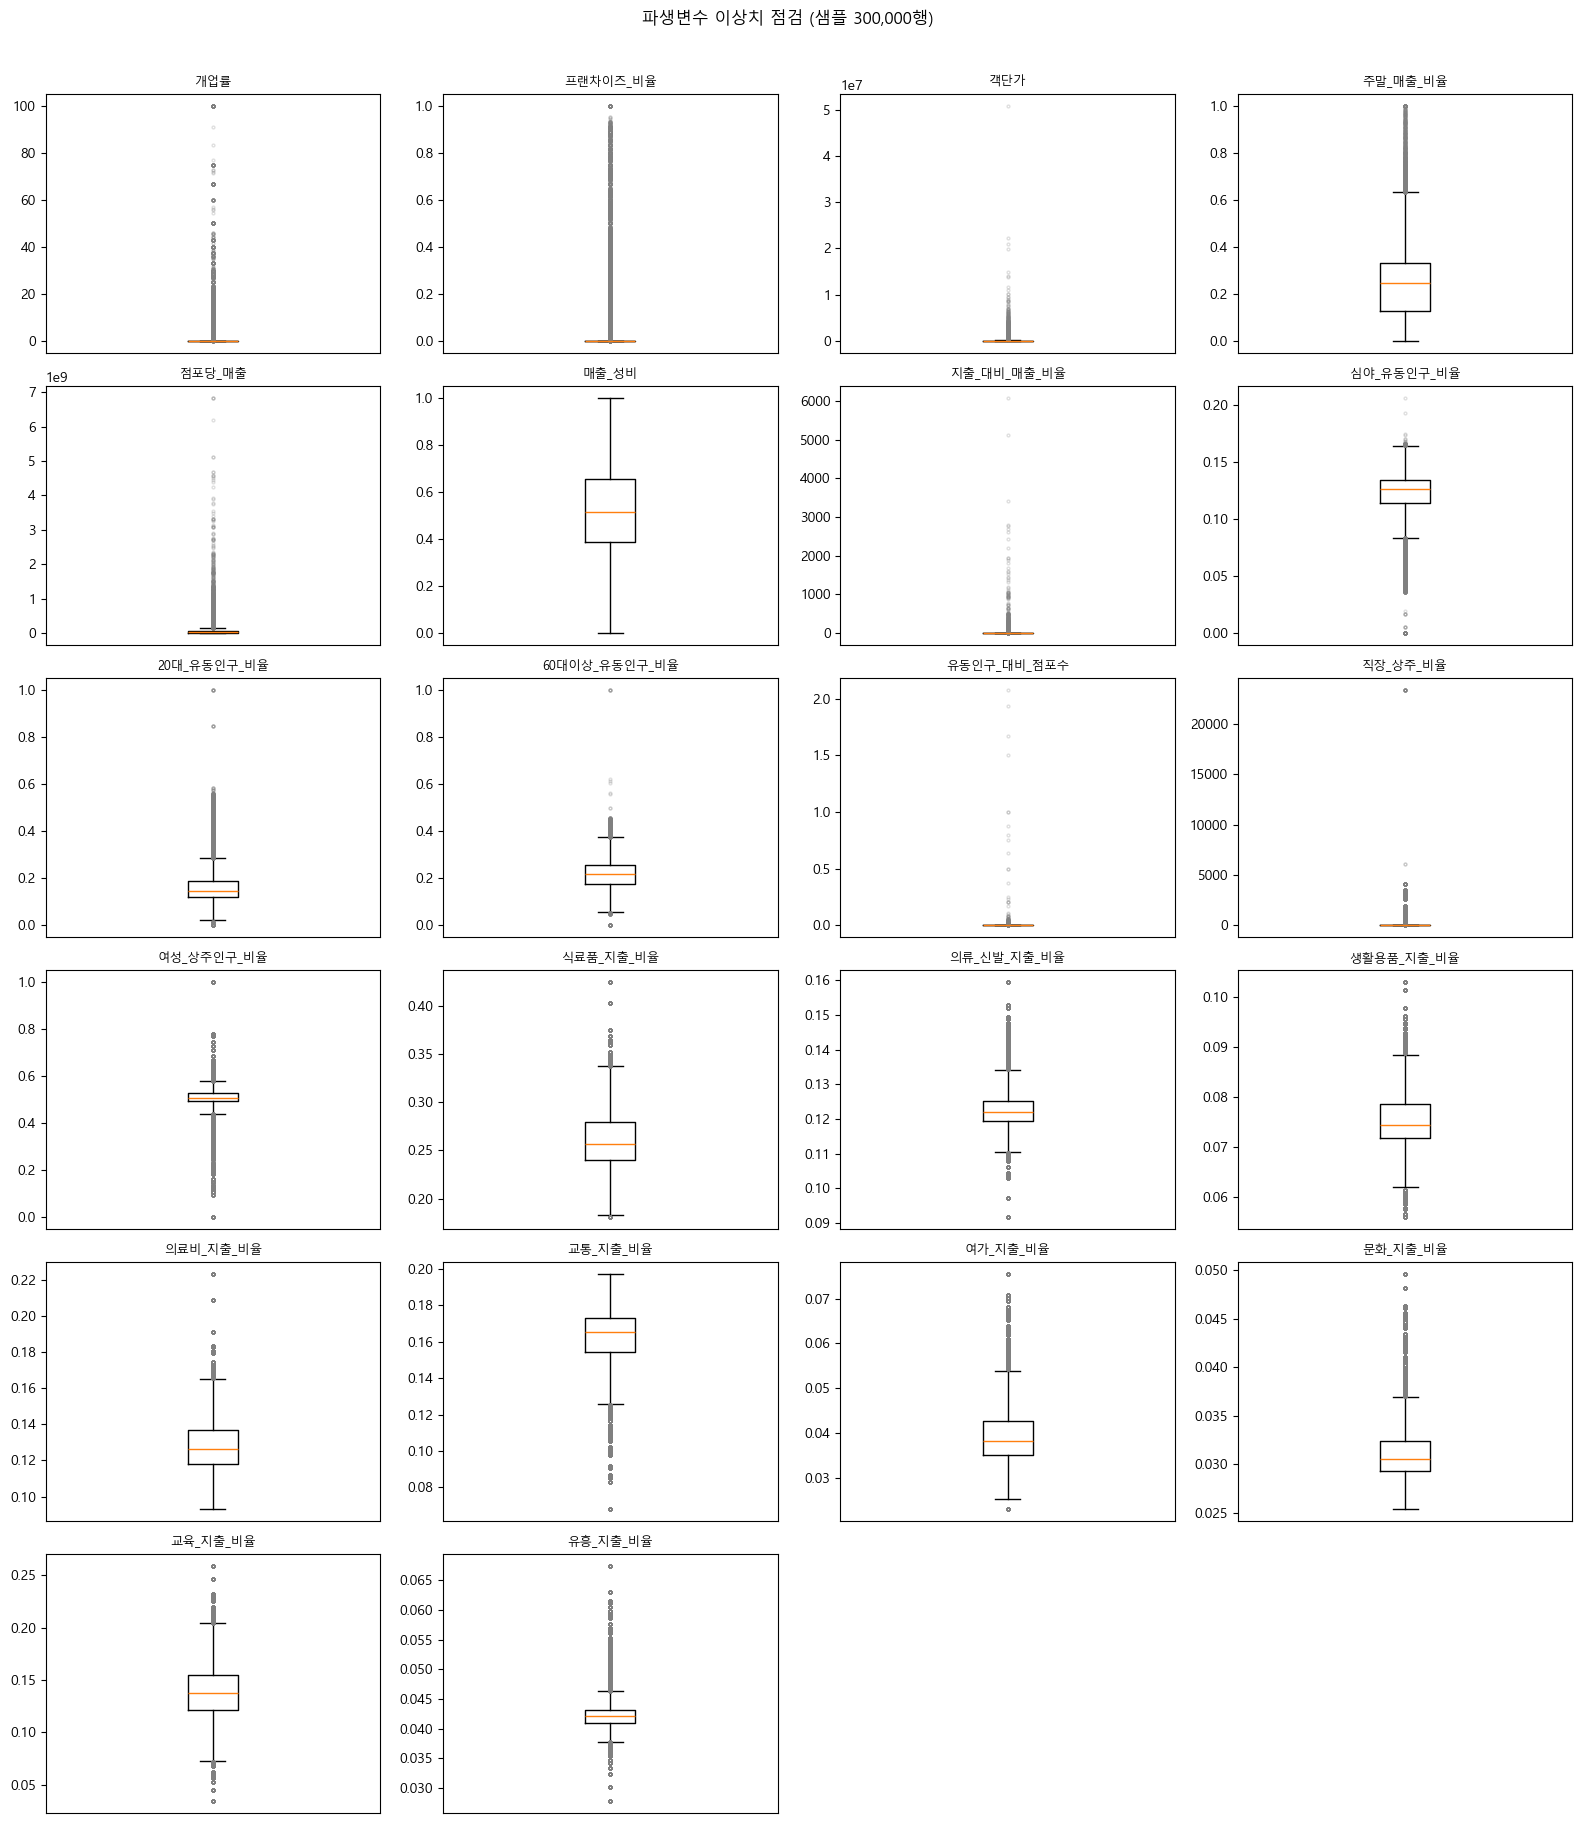

In [38]:
spend_categories = ['식료품', '의류_신발', '생활용품', '의료비', '교통', '여가', '문화', '교육', '유흥']
div_derived_cols = [
    '개업률', '프랜차이즈_비율', '객단가', '주말_매출_비율', '점포당_매출', '매출_성비',
    '지출_대비_매출_비율', '심야_유동인구_비율', '20대_유동인구_비율', '60대이상_유동인구_비율',
    '유동인구_대비_점포수', '직장_상주_비율', '여성_상주인구_비율',
] + [f'{c}_지출_비율' for c in spend_categories]

div_derived_cols = [c for c in div_derived_cols if c in train_df.columns]
sample_n = min(300_000, len(train_df))
sample_div = train_df[div_derived_cols].sample(sample_n, random_state=42)

n_cols = 4
n_rows = int(np.ceil(len(div_derived_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.flatten()

for i, col in enumerate(div_derived_cols):
    axes[i].boxplot(sample_div[col].dropna(),
                     flierprops=dict(markersize=2, alpha=0.25, markeredgecolor='gray'))
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xticks([])

for j in range(len(div_derived_cols), len(axes)):
    axes[j].axis('off')

fig.suptitle(f'파생변수 이상치 점검 (샘플 {sample_n:,}행)', y=1.01)
plt.tight_layout()
plt.show()


## 요약

- **1단계**: 7개 서울시 상권분석서비스 원본 데이터셋을 상권×업종×분기 단위로 병합
- **2단계**: 중복/불필요 컬럼 삭제, 결측 플래그 추가, 폐업률 이상치(100% 초과) 제거, 다음 분기 폐업률(y) 라벨 생성 → 학습용(y 있음) / 예측대상(y 없음, 최근 분기) 분리
- **3단계**: 점포·매출·소비·유동인구·인구구성 파생변수 생성 (학습용/예측대상 동일 함수 적용)
- **4단계**: 다중공선성 높은 컬럼 정리 (연령대 상주인구는 비율로 대체, 나머지는 삭제)
- **5단계**: 결측률/무한대/범위/패널연속성/상관관계/이상치를 그래프로 검증
